# Underfitting y overfitting

En este notebook veremos, con ejemplos sencillos en Python y scikit-learn:

1. Qué significa que un modelo **generalice**.
2. Qué son el **underfitting** (subajuste) y el **overfitting** (sobreajuste).
3. Cómo **detectarlos** comparando el error en entrenamiento y en test.
4. Cómo **corregirlos**.
5. Un **ejercicio** de consolidación.

## 1. La idea clave: generalizar

Entrenamos un modelo con unos datos (**entrenamiento**), pero lo que nos interesa es que funcione bien con datos **nuevos** que nunca ha visto.

Por eso siempre separamos los datos en dos partes:

- **Train**: para que el modelo aprenda.
- **Test**: para medir cómo se comporta con datos nuevos.

Comparar el rendimiento en *train* y en *test* es la herramienta principal para diagnosticar el problema.

## 2. Los tres escenarios

| | Underfitting | Buen ajuste | Overfitting |
|---|---|---|---|
| **Qué pasa** | El modelo es demasiado **simple**: no capta el patrón | Capta el patrón y no el ruido | El modelo es demasiado **complejo**: memoriza también el ruido |
| **Error en train** | Alto | Bajo | Muy bajo (casi 0) |
| **Error en test** | Alto | Bajo | Alto |
| **Analogía** | Un alumno que no ha estudiado | Un alumno que entiende la materia | Un alumno que memorizó las respuestas del examen del año pasado |
| **Término técnico** | Alto **sesgo** (*bias*) | Equilibrio | Alta **varianza** |

**Regla práctica:**
- Train malo y test malo → **underfitting**.
- Train muy bueno, pero test mucho peor → **overfitting**.

## 3. Preparación

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error

np.random.seed(1)

## 4. Ejemplo 1: regresión polinómica

Generamos datos que siguen una curva (un seno) con algo de **ruido**. Después ajustamos tres modelos de complejidad creciente:

- **Grado 1** (una recta): demasiado simple.
- **Grado 4**: complejidad razonable.
- **Grado 15**: demasiado complejo.

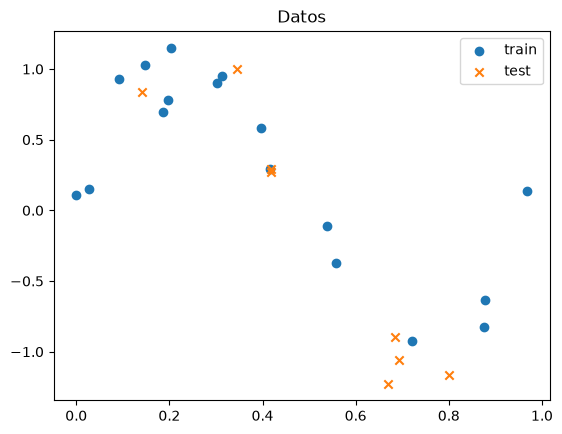

In [2]:
# Datos: y = sin(2*pi*x) + ruido
n = 25
X = np.sort(np.random.rand(n)).reshape(-1, 1)
y = np.sin(2 * np.pi * X).ravel() + np.random.normal(0, 0.2, n)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1)

plt.scatter(X_train, y_train, label="train")
plt.scatter(X_test, y_test, label="test", marker="x")
plt.legend(); plt.title("Datos"); plt.show()

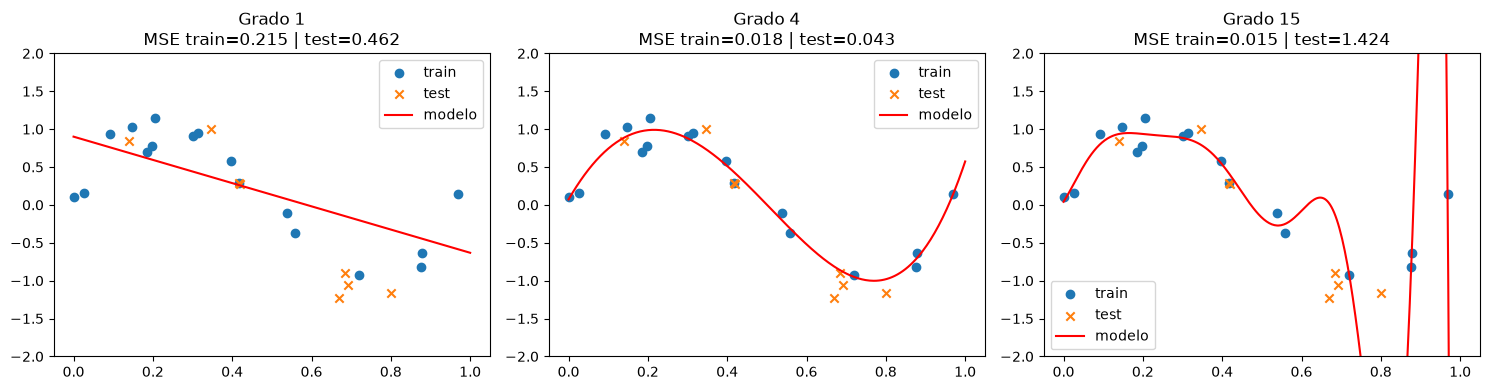

In [3]:
grados = [1, 4, 15]
X_plot = np.linspace(0, 1, 300).reshape(-1, 1)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, grado in zip(axes, grados):
    modelo = make_pipeline(PolynomialFeatures(grado), LinearRegression())
    modelo.fit(X_train, y_train)

    mse_train = mean_squared_error(y_train, modelo.predict(X_train))
    mse_test = mean_squared_error(y_test, modelo.predict(X_test))

    ax.scatter(X_train, y_train, label="train")
    ax.scatter(X_test, y_test, marker="x", label="test")
    ax.plot(X_plot, modelo.predict(X_plot), color="red", label="modelo")
    ax.set_ylim(-2, 2)
    ax.set_title(f"Grado {grado}\nMSE train={mse_train:.3f} | test={mse_test:.3f}")
    ax.legend()
plt.tight_layout(); plt.show()

**Qué observamos:**

- **Grado 1 → underfitting.** Una recta no puede seguir la curva y el error es alto tanto en train como en test.
- **Grado 4 → buen ajuste.** Sigue la forma general y los errores en train y en test son bajos y parecidos.
- **Grado 15 → overfitting.** La curva pasa por casi todos los puntos de train (error casi 0), pero hace cosas raras entre ellos, y el error en test se dispara.

## 5. Ejemplo 2: la curva de complejidad

En lugar de probar 3 grados, probamos muchos y dibujamos el error de train y de test según la complejidad. Es la forma más clara de **ver** dónde está el punto óptimo.

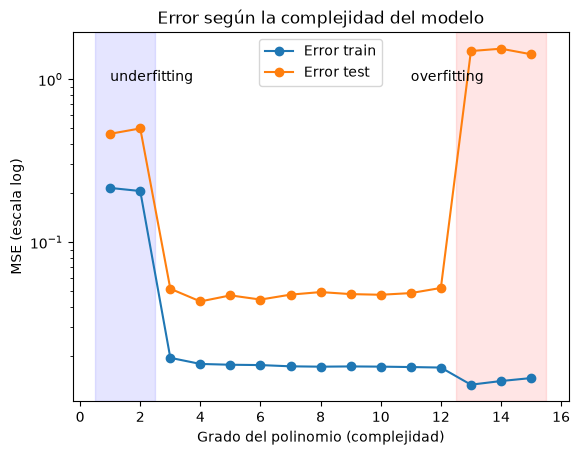

Mejor grado según test: 4


In [4]:
grados = range(1, 16)
err_train, err_test = [], []

for grado in grados:
    modelo = make_pipeline(PolynomialFeatures(grado), LinearRegression())
    modelo.fit(X_train, y_train)
    err_train.append(mean_squared_error(y_train, modelo.predict(X_train)))
    err_test.append(mean_squared_error(y_test, modelo.predict(X_test)))

plt.plot(grados, err_train, "o-", label="Error train")
plt.plot(grados, err_test, "o-", label="Error test")
plt.yscale("log")
plt.xlabel("Grado del polinomio (complejidad)")
plt.ylabel("MSE (escala log)")
plt.axvspan(0.5, 2.5, alpha=0.1, color="blue")
plt.axvspan(12.5, 15.5, alpha=0.1, color="red")
plt.text(1, plt.ylim()[1] * 0.5, "underfitting")
plt.text(11, plt.ylim()[1] * 0.5, "overfitting")
plt.legend(); plt.title("Error según la complejidad del modelo"); plt.show()

print("Mejor grado según test:", grados[int(np.argmin(err_test))])

**Cómo se lee:**

- El **error de train** baja siempre al aumentar la complejidad: el modelo se ajusta cada vez más a esos datos.
- El **error de test** baja al principio y luego **vuelve a subir**: a partir de cierto punto, el modelo aprende ruido.
- La zona buena es la del **mínimo del error de test**.

## 6. Ejemplo 3: árboles de decisión con `validation_curve`

Esto no es exclusivo de la regresión polinómica: le pasa a cualquier modelo. En un árbol de decisión, la complejidad la controla `max_depth`.

Usamos `validation_curve`, que hace validación cruzada por nosotros y calcula la puntuación (*accuracy*) en train y en validación para cada valor del parámetro.

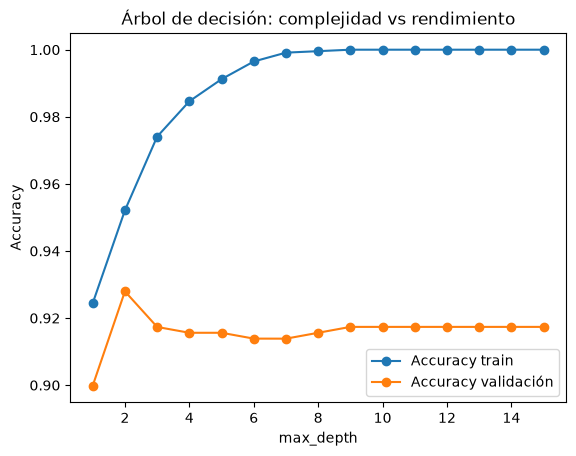

In [5]:
from sklearn.datasets import load_breast_cancer
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import validation_curve

Xc, yc = load_breast_cancer(return_X_y=True)

profundidades = range(1, 16)
train_scores, val_scores = validation_curve(
    DecisionTreeClassifier(random_state=0), Xc, yc,
    param_name="max_depth", param_range=profundidades, cv=5,
)

plt.plot(profundidades, train_scores.mean(axis=1), "o-", label="Accuracy train")
plt.plot(profundidades, val_scores.mean(axis=1), "o-", label="Accuracy validación")
plt.xlabel("max_depth"); plt.ylabel("Accuracy")
plt.legend(); plt.title("Árbol de decisión: complejidad vs rendimiento"); plt.show()

Ahora la métrica es un **acierto** (cuanto más alto, mejor), así que la gráfica está "dada la vuelta" respecto a la anterior:

- Con `max_depth` pequeño, ambas puntuaciones son algo más bajas → tendencia al **underfitting**.
- Al crecer la profundidad, la accuracy de train llega a **1.0** (el árbol memoriza), pero la de validación no mejora o empeora → **overfitting**.   

*Qué muestra la gráfica*:

- Con **profundidad 1** hay ***underfitting***: las dos curvas están bajas.
- **Profundidad 2** es el ***punto óptimo***: tiene la mejor accuracy en validación (0.928) y además la menor variabilidad entre folds.
- **A partir de 3** hay ***overfitting***: el train sigue subiendo hasta 1.0 a partir de profundidad 9, pero la validación baja y se queda en torno a 0.915. El hueco entre las dos curvas se hace cada vez más grande.

## 7. ¿Cómo se corrige?

| Si tienes **underfitting** | Si tienes **overfitting** |
|---|---|
| Usar un modelo más complejo | Usar un modelo más simple |
| Añadir variables (*features*) más informativas | Conseguir **más datos** de entrenamiento |
| Reducir la regularización | Aumentar la **regularización** |
| Entrenar más tiempo (redes neuronales) | Limitar la complejidad (`max_depth`, `min_samples_leaf`...) |
| | Usar *ensembles* (p. ej. Random Forest) |

Veamos uno de los remedios del overfitting: la **regularización**. `Ridge` es una regresión lineal que penaliza los coeficientes grandes. El parámetro `alpha` controla la fuerza de la penalización.

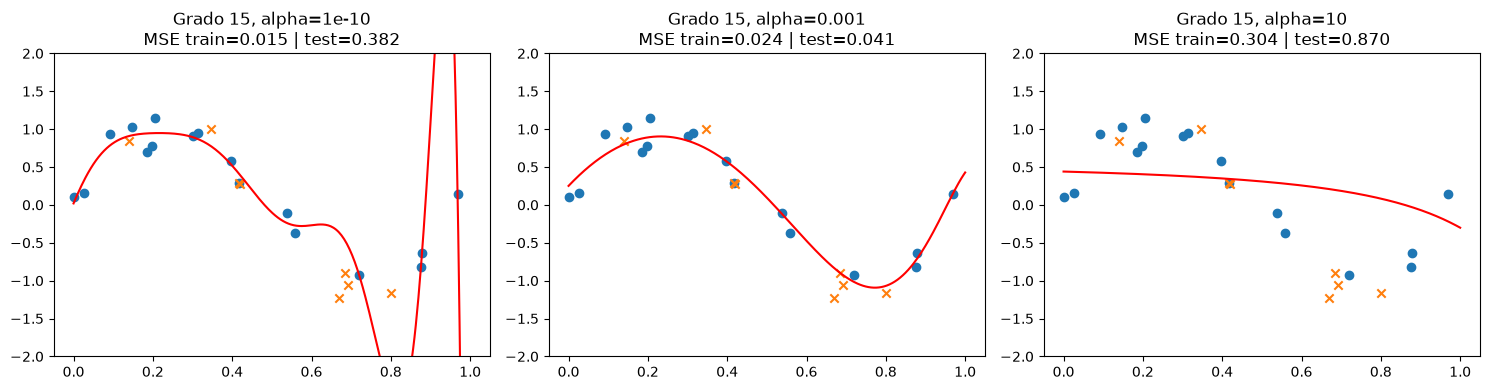

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, alpha in zip(axes, [1e-10, 1e-3, 10]):
    modelo = make_pipeline(PolynomialFeatures(15), Ridge(alpha=alpha))
    modelo.fit(X_train, y_train)
    mse_train = mean_squared_error(y_train, modelo.predict(X_train))
    mse_test = mean_squared_error(y_test, modelo.predict(X_test))

    ax.scatter(X_train, y_train); ax.scatter(X_test, y_test, marker="x")
    ax.plot(X_plot, modelo.predict(X_plot), color="red")
    ax.set_ylim(-2, 2)
    ax.set_title(f"Grado 15, alpha={alpha}\nMSE train={mse_train:.3f} | test={mse_test:.3f}")
plt.tight_layout(); plt.show()

Con el **mismo polinomio de grado 15**:

- `alpha` casi 0 → sin regularización → **overfitting**.
- `alpha` moderado → la curva se suaviza y el error de test baja.
- `alpha` muy grande → penalizamos demasiado y el modelo se vuelve casi plano → **underfitting**.

La regularización también es un "mando" de complejidad, y los dos extremos son malos.

## 8. Resumen

- **Underfitting:** modelo demasiado simple. Error alto en train **y** en test.
- **Overfitting:** modelo demasiado complejo. Error muy bajo en train, pero alto en test.
- Para diagnosticar, compara **siempre** el rendimiento en train y en test (o validación).
- El objetivo es encontrar la complejidad en la que el **error de test es mínimo**.

---
## 9. Ejercicio de consolidación

Vamos a trabajar con el clasificador **K vecinos más cercanos (KNN)**. Su hiperparámetro `n_neighbors` (K) controla la complejidad, pero **al revés** de lo que podrías esperar:

- **K pequeño** (p. ej. 1): el modelo decide mirando solo el vecino más cercano.
- **K grande** (p. ej. 150): el modelo decide mirando a muchísimos vecinos.

Usaremos un dataset sintético con forma de dos "lunas" entrelazadas (`make_moons`).

### Tareas

1. Divide los datos en train (70 %) y test (30 %) con `random_state=42`.
2. Entrena un `KNeighborsClassifier` para cada valor de K en `range(1, 151, 5)` y guarda la *accuracy* en train y en test.
3. Dibuja ambas curvas en una misma gráfica (eje X: K, eje Y: accuracy).
4. Responde en la celda de texto:
   - ¿Con qué valores de K hay **overfitting**? ¿Cómo lo sabes?
   - ¿Con qué valores de K hay **underfitting**? ¿Cómo lo sabes?
   - ¿Qué valor de K elegirías?
5. **(Extra)** Repite el experimento con `noise=0.1` y con `noise=0.5`. ¿Cambia el mejor valor de K? ¿Por qué crees que pasa?

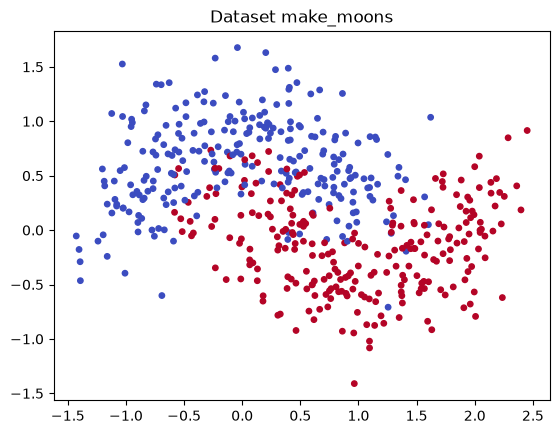

In [7]:
from sklearn.datasets import make_moons
from sklearn.neighbors import KNeighborsClassifier

X_ej, y_ej = make_moons(n_samples=500, noise=0.3, random_state=0)

plt.scatter(X_ej[:, 0], X_ej[:, 1], c=y_ej, cmap="coolwarm", s=15)
plt.title("Dataset make_moons"); plt.show()

In [ ]:
# 1. Divide en train y test
# TU CÓDIGO AQUÍ


# 2. Entrena un KNN para cada K y guarda las accuracies
valores_k = range(1, 151, 5)
acc_train, acc_test = [], []
# TU CÓDIGO AQUÍ


# 3. Dibuja las dos curvas
# TU CÓDIGO AQUÍ

**4. Tus respuestas:**

- Overfitting con K = ... porque ...
- Underfitting con K = ... porque ...
- Elegiría K = ... porque ...

---
## Solución propuesta

*Intenta hacer el ejercicio antes de mirar esta parte.*

In [ ]:
X_tr, X_te, y_tr, y_te = train_test_split(X_ej, y_ej, test_size=0.3, random_state=42)

valores_k = range(1, 151, 5)
acc_train, acc_test = [], []
for k in valores_k:
    knn = KNeighborsClassifier(n_neighbors=k).fit(X_tr, y_tr)
    acc_train.append(knn.score(X_tr, y_tr))
    acc_test.append(knn.score(X_te, y_te))

plt.plot(valores_k, acc_train, "o-", label="Accuracy train")
plt.plot(valores_k, acc_test, "o-", label="Accuracy test")
plt.xlabel("K (n_neighbors)"); plt.ylabel("Accuracy")
plt.legend(); plt.title("KNN: efecto de K"); plt.show()

mejor_k = list(valores_k)[int(np.argmax(acc_test))]
print(f"Mejor K según test: {mejor_k} (accuracy test = {max(acc_test):.3f})")

**Interpretación:**

- **K = 1 → overfitting.** La accuracy de train es 1.0, porque cada punto es su propio vecino más cercano y el modelo "memoriza". La accuracy de test es claramente menor.
- **K muy grande → underfitting.** El modelo promedia sobre tantos vecinos que la frontera de decisión se vuelve demasiado simple. Bajan tanto train como test.
- **K intermedio** → es donde la accuracy de test es máxima. Ese es el valor a elegir.
- **Extra:** con más ruido (`noise=0.5`), suele convenir un K mayor, porque promediar sobre más vecinos ayuda a ignorar el ruido. Con poco ruido (`noise=0.1`), valen K más pequeños.

> Nota: para elegir hiperparámetros de forma rigurosa, se debería usar **validación cruzada** sobre el train (como `validation_curve` en el ejemplo 3) y reservar el test solo para la evaluación final. Aquí usamos el test directamente para simplificar.